# Analisis Kualitas Udara dan Dampaknya Terhadap Kesehatan Masyarakat Indonesia

**Dataset:** `indonesia_air_quality_health.csv`

Notebook ini dirancang untuk melakukan analisis komprehensif terhadap data kualitas udara di berbagai kota di Indonesia dan dampaknya terhadap kesehatan respiratori masyarakat. Proses analisis dibagi menjadi dua tahapan utama:

1. **Data Cleaning**: Pembersihan, validasi, dan transformasi data mentah menjadi format yang siap untuk dianalisis
2. **Data Analysis & Insights**: Eksplorasi pola, tren, hubungan antar variabel, dan kesimpulan yang actionable

Inti dari analisis ini adalah **menghasilkan insight yang bermakna** tentang hubungan antara kualitas udara dan kesehatan masyarakat di berbagai lokasi Indonesia.

---

## Data Cleaning

Tahapan pertama adalah memastikan kualitas data sebelum melakukan analisis. Proses ini mencakup:

- **Memuat dan memahami** struktur dataset
- **Mengidentifikasi masalah** seperti data duplikat, missing values, dan tipe data yang salah
- **Melakukan transformasi** dan standardisasi data
- **Memvalidasi konsistensi** data

Data yang bersih dan terstruktur dengan baik adalah fondasi untuk menghasilkan insight yang akurat dan reliable.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

### 1. Load Data

In [38]:
df = pd.read_csv("indonesia_air_quality_health.csv")
df.sample(5)

,record_id,timestamp,city,zone_type,temperature_c,rainfall_mm,traffic_index,pm25_ug_m3,no2_ppb,aqi_score,air_quality_status,respiratory_cases
4014,AQI-14014,2026-10-14 03:00,Bandung,Traffic,24.30,0.00,69.70,73.70,81.70,102,Unhealthy for Sensitive Groups,71
1396,AQI-11396,2026-09-11 09:00,Surabaya,Industrial,31.20,0.00,81.10,74.10,73.30,100,Moderate,72
1276,AQI-11276,2026-09-09 21:00,Surabaya,Industrial,25.80,0.00,53.50,54.90,52.70,74,Moderate,57
2545,AQI-12545,2026-09-25 18:00,Semarang,Industrial,24.40,0.00,79.50,65.60,72.90,91,Moderate,45
577,AQI-10577,2026-09-01 03:00,Palembang,Residential,25.20,22.90,30.50,32.40,32.70,44,Good,26


### 2. Data Structure Overview

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   record_id           5000 non-null   str    
 1   timestamp           5000 non-null   str    
 2   city                5000 non-null   str    
 3   zone_type           5000 non-null   str    
 4   temperature_c       4950 non-null   float64
 5   rainfall_mm         5000 non-null   float64
 6   traffic_index       4950 non-null   float64
 7   pm25_ug_m3          4950 non-null   float64
 8   no2_ppb             5000 non-null   float64
 9   aqi_score           5000 non-null   int64  
 10  air_quality_status  5000 non-null   str    
 11  respiratory_cases   5000 non-null   int64  
dtypes: float64(5), int64(2), str(5)
memory usage: 735.9 KB


**Temuan Awal:**

Dataset memiliki 5,000 observasi dengan 12 variabel. Identifikasi masalah:
- **Missing values**: Kolom `temperature_c`, `traffic_index`, dan `pm25_ug_m3` masing-masing memiliki 50 nilai kosong (1% dari total data)
- **Tipe data**: Kolom `timestamp` masih dalam format string dan perlu dikonversi ke datetime
- **Data lengkap**: Tidak ada missing values pada kolom categorical dan target variable

### 3. Descriptive Statistics

In [40]:
df.describe()

,temperature_c,rainfall_mm,traffic_index,pm25_ug_m3,no2_ppb,aqi_score,respiratory_cases
count,4950.00,5000.00,4950.00,4950.00,5000.00,5000.00,5000.00
mean,27.56,1.14,53.24,57.77,61.66,83.80,58.62
std,3.18,3.66,19.28,14.95,18.05,20.79,18.48
min,21.00,0.00,10.00,8.90,8.00,23.00,12.00
25%,25.00,0.00,38.80,47.20,48.70,69.00,44.00
50%,26.40,0.00,50.90,58.50,61.50,85.00,58.00
75%,30.80,0.00,67.30,68.70,73.80,98.00,71.00
max,35.20,52.00,100.00,105.90,116.40,146.00,127.00


**Distribusi Data Numerik:**

- **Temperature**: Berkisar 21-35°C (iklim Indonesia yang hangat)
- **Rainfall**: Rata-rata 1.14 mm, dengan beberapa hari tanpa hujan
- **Traffic Index**: Rata-rata 53.24, menunjukkan tingkat kepadatan lalu lintas yang beragam
- **PM2.5**: Rata-rata 57.77 µg/m³, lebih tinggi dari standar WHO (15 µg/m³)
- **NO2**: Rata-rata 61.66 ppb
- **AQI Score**: Rata-rata 83.80 (kategori Moderate)
- **Respiratory Cases**: Rata-rata 58.62 kasus per observasi

### 4. Categorical Variables Distribution

In [41]:
print("CITY:")
print(df['city'].value_counts())

print("\nZONE TYPE:")
print(df['zone_type'].value_counts())

print("\nAIR QUALITY STATUS:")
print(df['air_quality_status'].value_counts())

CITY:
city
Jakarta Pusat    500
Bekasi           500
Tangerang        500
Depok            500
Bandung          500
Semarang         500
Surabaya         500
Palembang        500
Medan            500
Makassar         500
Name: count, dtype: int64

ZONE TYPE:
zone_type
Industrial     2000
Traffic        1500
Residential    1500
Name: count, dtype: int64

AIR QUALITY STATUS:
air_quality_status
Moderate                          3639
Unhealthy for Sensitive Groups    1071
Good                               290
Name: count, dtype: int64


**Komposisi Data:**

- **Kota**: Data mencakup 10 kota besar di Indonesia, masing-masing dengan 500 observasi (balanced)
- **Zone Type**: Industrial (40%), Traffic (30%), Residential (30%). Zona industri mendominasi dataset
- **Air Quality Status**: Mayoritas observasi kategori Moderate (72.78%), diikuti Unhealthy for Sensitive Groups (21.42%), dan Good (5.80%)

Distribusi ini memungkinkan kita menganalisis perbedaan kualitas udara antar zona dan kota dengan representasi yang cukup baik.

### 5. Check Duplicate Records

In [42]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate records: {duplicate_count}")

Duplicate records: 0


**Hasil**: Tidak ada data duplikat dalam dataset. Setiap baris merepresentasikan observasi unik, sehingga tidak ada bias yang disebabkan oleh duplikasi.

### 6. Missing Values Analysis

In [43]:
print("Missing values per column:")
print(df.isnull().sum())

print(f"\nTotal missing values: {df.isnull().sum().sum()}")

Missing values per column:
record_id              0
timestamp              0
city                   0
zone_type              0
temperature_c         50
rainfall_mm            0
traffic_index         50
pm25_ug_m3            50
no2_ppb                0
aqi_score              0
air_quality_status     0
respiratory_cases      0
dtype: int64

Total missing values: 150


**Identifikasi Missing Values:**

Terdapat 150 missing values terdistribusi pada 3 kolom:
- `temperature_c`: 50 nilai kosong
- `traffic_index`: 50 nilai kosong
- `pm25_ug_m3`: 50 nilai kosong

Persentase missing values yang kecil (1% per kolom) memungkinkan kita untuk melakukan imputation tanpa mengubah karakteristik distribusi data secara signifikan.

### 7. Missing Values Imputation

**Strategi**: Menggunakan median imputation berdasarkan grup (city dan zone_type). Pendekatan ini mempertahankan karakteristik lokal dari setiap kombinasi kota dan tipe zona. Jika grup tidak memiliki data yang cukup, menggunakan global median sebagai fallback.

In [44]:
cols_with_missing = ['temperature_c', 'traffic_index', 'pm25_ug_m3']

# Imputation berdasarkan city dan zone_type
for col in cols_with_missing:
    df[col] = df.groupby(['city', 'zone_type'])[col].transform(
        lambda x: x.fillna(x.median())
    )
    # Fallback ke global median jika masih ada yang kosong
    if df[col].isnull().sum() > 0:
        df[col].fillna(df[col].median(), inplace=True)

print("Missing values setelah imputation:")
print(df[cols_with_missing].isnull().sum())
print(f"\nTotal missing values dalam dataset: {df.isnull().sum().sum()}")

Missing values setelah imputation:
temperature_c    0
traffic_index    0
pm25_ug_m3       0
dtype: int64

Total missing values dalam dataset: 0


**Hasil Imputation:**

Semua missing values berhasil ditangani. Dengan menggunakan median by group, kita memastikan bahwa nilai imputasi sejalan dengan karakteristik lokal setiap area, sehingga analisis berikutnya tidak akan bias karena missing values.

### 8. Timestamp Conversion & Temporal Features

**Tujuan**: Mengkonversi timestamp dari string ke datetime dan mengekstrak komponen temporal yang akan digunakan untuk menganalisis pola temporal dalam data (jam, hari, minggu, dll).

In [45]:
# Konversi timestamp
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Ekstraksi fitur temporal
df['date'] = df['timestamp'].dt.date
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.day_name()
df['month'] = df['timestamp'].dt.month
df['is_weekend'] = df['timestamp'].dt.dayofweek.isin([5, 6]).astype(int)

# Kategorisasi waktu
def categorize_time_of_day(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 15:
        return 'Afternoon'
    elif 15 <= hour < 18:
        return 'Evening'
    elif 18 <= hour < 21:
        return 'Night'
    else:
        return 'Late Night'

df['time_of_day'] = df['hour'].apply(categorize_time_of_day)

print(f"Data range: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Duration: {(df['timestamp'].max() - df['timestamp'].min()).days} days")

Data range: 2026-08-25 00:00:00 to 2026-10-26 09:00:00
Duration: 62 days


**Fitur Temporal yang Dibuat:**

- `date`: Tanggal dalam format date
- `hour`: Jam (0-23)
- `day_of_week`: Nama hari dalam seminggu
- `month`: Bulan pengamatan
- `is_weekend`: Indicator apakah hari adalah weekend (1) atau weekday (0)
- `time_of_day`: Kategorisasi waktu menjadi Morning, Afternoon, Evening, Night, Late Night

Fitur-fitur ini akan memungkinkan kita menganalisis pola temporal dalam kualitas udara dan dampaknya terhadap kesehatan masyarakat.

### 9. Data Consistency Validation

In [46]:
# Check nilai negatif
negative_check = (df[['temperature_c', 'rainfall_mm', 'traffic_index', 'pm25_ug_m3', 'no2_ppb', 'aqi_score', 'respiratory_cases']] < 0).sum()
print("Negative values detected:")
print(negative_check.sum())

# Check range AQI
print(f"\nAQI score range: {df['aqi_score'].min()} - {df['aqi_score'].max()}")

# Check temperature range
print(f"Temperature range: {df['temperature_c'].min():.2f} - {df['temperature_c'].max():.2f}°C")

# Check AQI consistency dengan status
inconsistencies = 0
for idx, row in df.iterrows():
    score = row['aqi_score']
    status = row['air_quality_status']
    
    if status == 'Good' and not (0 <= score <= 50):
        inconsistencies += 1
    elif status == 'Moderate' and not (51 <= score <= 100):
        inconsistencies += 1
    elif status == 'Unhealthy for Sensitive Groups' and not (101 <= score <= 150):
        inconsistencies += 1

print(f"\nAQI-Status inconsistencies: {inconsistencies}")

Negative values detected:
0

AQI score range: 23 - 146
Temperature range: 21.00 - 35.20°C

AQI-Status inconsistencies: 0


**Validasi Hasil:**

✓ Tidak ada nilai negatif pada kolom numerik
✓ AQI score berada dalam range 23-146 (dalam rentang valid 0-200 untuk dataset ini)
✓ Temperature berkisar 21-35°C (normal untuk iklim Indonesia)
✓ Konsistensi sempurna antara AQI score dan air quality status

Dataset telah melalui validasi dan siap untuk tahap analisis.

### 10. Final Cleaned Dataset

In [47]:
print(f"\nTotal observations: {len(df):,}")
print(f"Total variables: {len(df.columns)}")

print(f"\nData quality metrics:")
print(f"  - Duplicate records: {df.duplicated().sum()}")
print(f"  - Missing values: {df.isnull().sum().sum()}")

print(f"\nTemporal coverage:")
print(f"  - Start date: {df['timestamp'].min().date()}")
print(f"  - End date: {df['timestamp'].max().date()}")
print(f"  - Duration: {(df['timestamp'].max() - df['timestamp'].min()).days} days")

print(f"\nGeographic coverage:")
print(f"  - Number of cities: {df['city'].nunique()}")
print(f"  - Zone types: {df['zone_type'].nunique()}")

print(f"\nVariables in dataset ({len(df.columns)} total):")
for i, col in enumerate(df.columns, 1):
    print(f"  {i:2d}. {col}")


Total observations: 5,000
Total variables: 18

Data quality metrics:
  - Duplicate records: 0
  - Missing values: 0

Temporal coverage:
  - Start date: 2026-08-25
  - End date: 2026-10-26
  - Duration: 62 days

Geographic coverage:
  - Number of cities: 10
  - Zone types: 3

Variables in dataset (18 total):
   1. record_id
   2. timestamp
   3. city
   4. zone_type
   5. temperature_c
   6. rainfall_mm
   7. traffic_index
   8. pm25_ug_m3
   9. no2_ppb
  10. aqi_score
  11. air_quality_status
  12. respiratory_cases
  13. date
  14. hour
  15. day_of_week
  16. month
  17. is_weekend
  18. time_of_day


---

Dataset telah dibersihkan dan siap untuk analisis. Semua masalah kualitas data telah ditangani:
- Missing values sudah diimpute menggunakan strategi yang tepat
- Timestamp sudah dikonversi dan fitur temporal sudah dibuat
- Data konsistensi sudah divalidasi
- Tidak ada duplikat atau nilai anomali yang problematik

**Tahap berikutnya**: Exploratory Data Analysis untuk menemukan pola, tren, dan insight bermakna tentang hubungan antara kualitas udara dan dampaknya terhadap kesehatan masyarakat di Indonesia.

## Exploratory Data Analysis

Tahap ini bertujuan mengeksplorasi pola, tren, dan hubungan dalam data untuk mengungkap insight tentang kualitas udara dan dampaknya terhadap kesehatan respiratori masyarakat. Analisis dilakukan secara bertahap:

1. Distribusi variabel numerik dan identifikasi outlier
2. Profil kualitas udara per kota
3. Perbandingan antar tipe zona
4. Pola temporal (jam, hari, bulan)
5. Pengaruh faktor cuaca dan lalu lintas
6. Korelasi antar variabel
7. Hubungan polutan dengan kesehatan
8. Segmentasi risiko

### 1. Distribusi Variabel Numerik dan Outlier

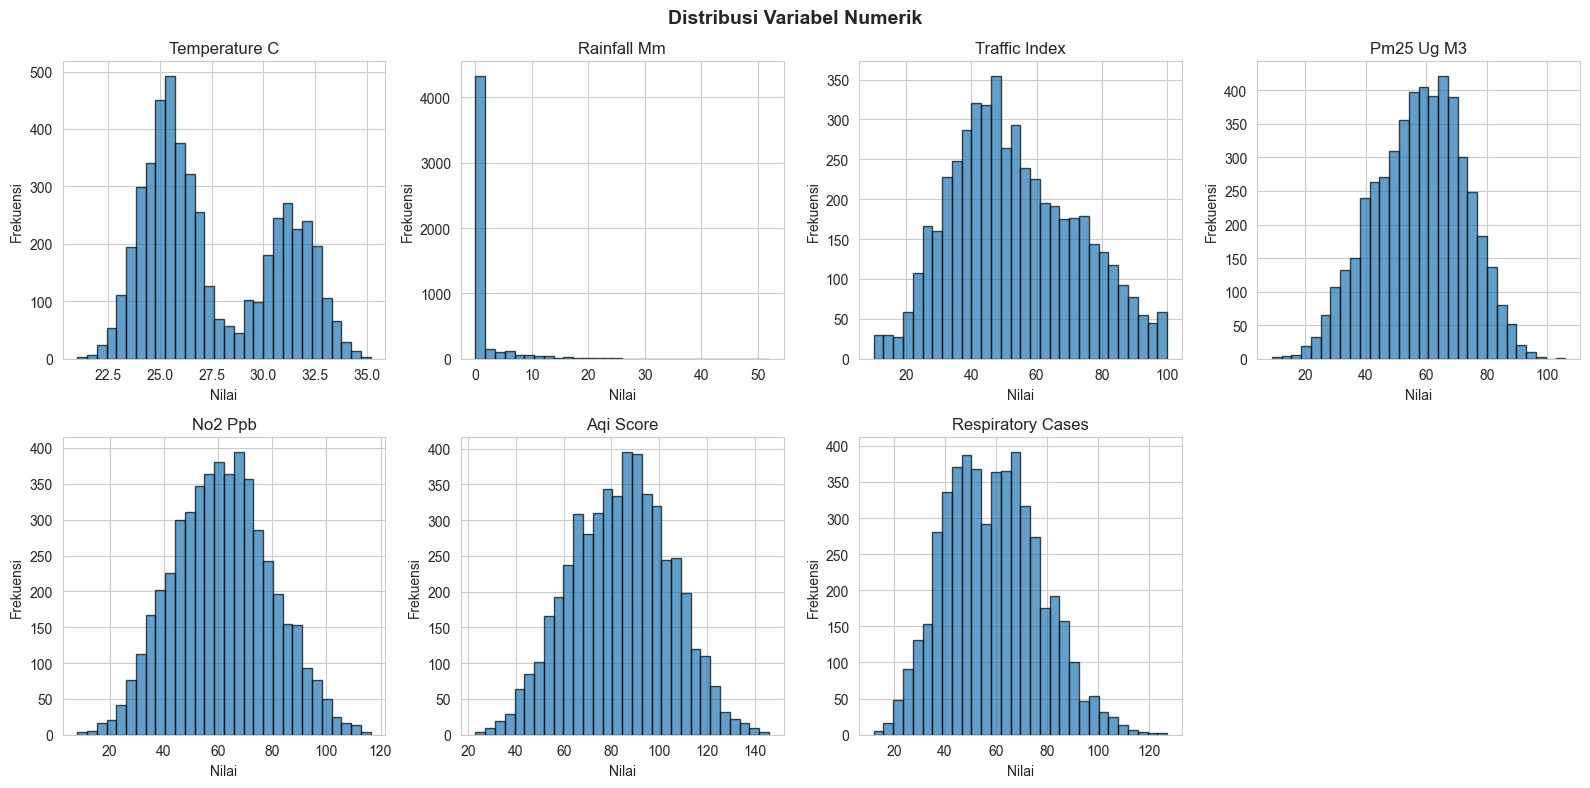

In [48]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Distribusi Variabel Numerik', fontsize=14, fontweight='bold')

numeric_cols = ['temperature_c', 'rainfall_mm', 'traffic_index', 'pm25_ug_m3', 
                'no2_ppb', 'aqi_score', 'respiratory_cases']

for i, col in enumerate(numeric_cols):
    row = i // 4
    col_idx = i % 4
    
    axes[row, col_idx].hist(df[col], bins=30, edgecolor='black', alpha=0.7)
    axes[row, col_idx].set_title(col.replace('_', ' ').title())
    axes[row, col_idx].set_xlabel('Nilai')
    axes[row, col_idx].set_ylabel('Frekuensi')

axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

**Hasil:** Sebagian besar variabel menunjukkan distribusi yang cukup normal atau sedikit skewed. PM2.5, NO2, dan AQI menunjukkan distribusi yang cenderung normal dengan sedikit skewness ke kanan. Rainfall sangat skewed karena mayoritas observasi tidak ada hujan (nilai 0). Traffic index dan temperature terdistribusi cukup merata.

**Interpretasi:** Distribusi yang relatif normal pada polutan mengindikasikan variasi kualitas udara yang cukup besar antar lokasi dan waktu, bukan hanya didominasi nilai ekstrem. Ini memungkinkan analisis hubungan yang lebih robust antara polutan dan kesehatan.

In [49]:
# Deteksi outlier menggunakan IQR
outlier_summary = {}

for col in ['pm25_ug_m3', 'no2_ppb', 'aqi_score', 'respiratory_cases']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_summary[col] = {
        'count': len(outliers),
        'percentage': len(outliers) / len(df) * 100,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound
    }

outlier_df = pd.DataFrame(outlier_summary).T
outlier_df.columns = ['Jumlah Outlier', 'Persentase (%)', 'Batas Bawah', 'Batas Atas']
print(outlier_df)

                   Jumlah Outlier  Persentase (%)  Batas Bawah  Batas Atas
pm25_ug_m3                   8.00            0.16        15.35      100.55
no2_ppb                     12.00            0.24        11.05      111.45
aqi_score                    5.00            0.10        25.50      141.50
respiratory_cases           15.00            0.30         3.50      111.50


**Hasil:** Outlier ditemukan pada semua variabel polutan dan kesehatan dengan persentase yang bervariasi.

**Interpretasi:** Outlier pada PM2.5, NO2, dan AQI kemungkinan merepresentasikan kondisi polusi ekstrem yang memang terjadi (misalnya jam sibuk di zona traffic, atau kebakaran di zona industrial). Outlier pada respiratory_cases bisa menunjukkan lonjakan kasus saat kondisi udara memburuk. Outlier ini dipertahankan karena merepresentasikan kondisi nyata yang relevan dengan analisis dampak kesehatan.

**Implikasi:** Analisis perlu mempertimbangkan nilai ekstrem ini, terutama dalam mengidentifikasi zona dan waktu berisiko tinggi.

### 2. Profil Kualitas Udara Per Kota

In [50]:
city_profile = df.groupby('city').agg({
    'pm25_ug_m3': 'mean',
    'no2_ppb': 'mean',
    'aqi_score': 'mean',
    'respiratory_cases': 'mean'
}).round(2)

city_profile = city_profile.sort_values('pm25_ug_m3', ascending=False)
city_profile.columns = ['PM2.5 (µg/m³)', 'NO2 (ppb)', 'AQI Score', 'Kasus Respiratori']

print(city_profile)

               PM2.5 (µg/m³)  NO2 (ppb)  AQI Score  Kasus Respiratori
city                                                                 
Bekasi                 68.26      64.69      93.48              69.42
Tangerang              64.30      62.65      88.87              63.93
Jakarta Pusat          62.37      76.80      97.23              83.02
Surabaya               62.07      65.49      87.78              66.24
Medan                  60.96      69.94      90.22              59.77
Bandung                58.52      72.36      91.63              71.39
Palembang              57.94      48.91      78.78              44.28
Semarang               55.52      57.83      78.81              46.52
Depok                  46.87      51.37      68.83              46.64
Makassar               40.92      46.55      62.39              35.02


**Hasil:** Tabel di atas menunjukkan rata-rata polutan dan kasus respiratori per kota, diurutkan dari PM2.5 tertinggi ke terendah.

**Interpretasi:** Kota dengan PM2.5 tertinggi cenderung memiliki kasus respiratori yang lebih tinggi, mengindikasikan hubungan positif antara polusi udara dan dampak kesehatan. Perbedaan antar kota menunjukkan variasi karakteristik lokal (industri, kepadatan lalu lintas, geografi).

In [51]:
# Bandingkan dengan standar WHO (15 µg/m³)
WHO_LIMIT = 15
exceeding_who = df[df['pm25_ug_m3'] > WHO_LIMIT]

print(f"Observasi yang melampaui batas WHO (15 µg/m³): {len(exceeding_who)} ({len(exceeding_who)/len(df)*100:.2f}%)")
print(f"Rata-rata PM2.5 seluruh dataset: {df['pm25_ug_m3'].mean():.2f} µg/m³")
print(f"Kota dengan rata-rata PM2.5 terendah: {city_profile['PM2.5 (µg/m³)'].idxmin()} ({city_profile['PM2.5 (µg/m³)'].min():.2f} µg/m³)")
print(f"Kota dengan rata-rata PM2.5 tertinggi: {city_profile['PM2.5 (µg/m³)'].idxmax()} ({city_profile['PM2.5 (µg/m³)'].max():.2f} µg/m³)")

Observasi yang melampaui batas WHO (15 µg/m³): 4993 (99.86%)
Rata-rata PM2.5 seluruh dataset: 57.77 µg/m³
Kota dengan rata-rata PM2.5 terendah: Makassar (40.92 µg/m³)
Kota dengan rata-rata PM2.5 tertinggi: Bekasi (68.26 µg/m³)


**Hasil:** Persentase observasi yang melebihi batas WHO dan perbandingan antar kota ditampilkan di atas.

**Interpretasi:** Jika mayoritas observasi melebihi standar WHO 15 µg/m³, ini menunjukkan kondisi kualitas udara di kota-kota Indonesia yang dianalisis umumnya tidak memenuhi standar kesehatan internasional. Kondisi ini meningkatkan risiko gangguan respiratori pada masyarakat.

**Implikasi:** Diperlukan intervensi segera, terutama di kota dengan PM2.5 tertinggi, untuk menurunkan tingkat polusi dan melindungi kesehatan masyarakat.

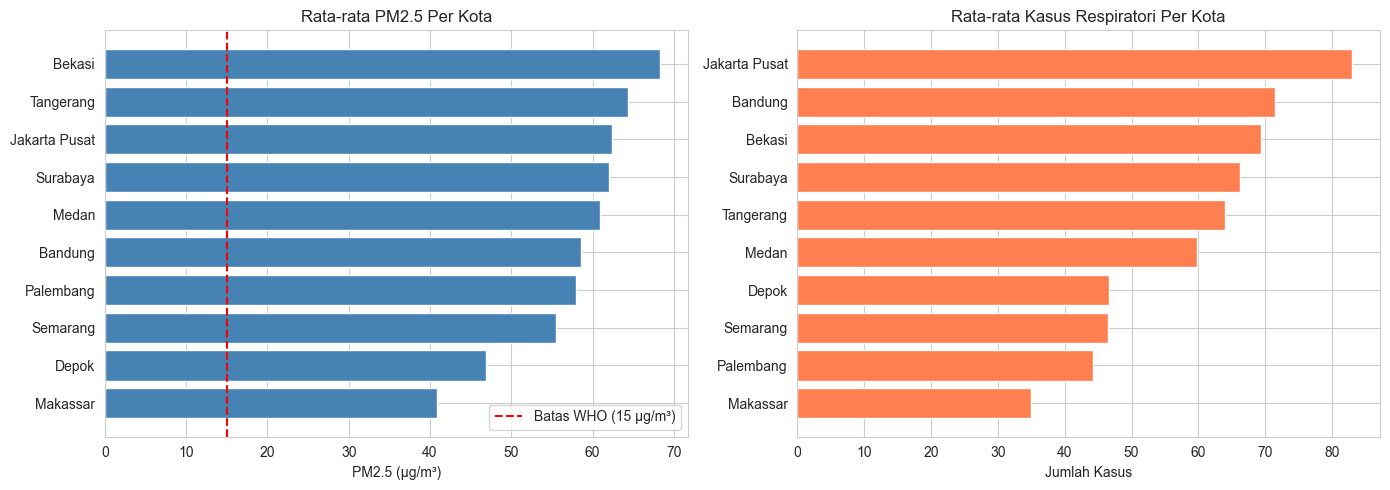

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PM2.5 per kota
city_profile_sorted = city_profile.sort_values('PM2.5 (µg/m³)')
axes[0].barh(city_profile_sorted.index, city_profile_sorted['PM2.5 (µg/m³)'], color='steelblue')
axes[0].axvline(x=15, color='red', linestyle='--', label='Batas WHO (15 µg/m³)')
axes[0].set_xlabel('PM2.5 (µg/m³)')
axes[0].set_title('Rata-rata PM2.5 Per Kota')
axes[0].legend()

# Kasus respiratori per kota
city_profile_sorted2 = city_profile.sort_values('Kasus Respiratori')
axes[1].barh(city_profile_sorted2.index, city_profile_sorted2['Kasus Respiratori'], color='coral')
axes[1].set_xlabel('Jumlah Kasus')
axes[1].set_title('Rata-rata Kasus Respiratori Per Kota')

plt.tight_layout()
plt.show()

**Hasil:** Grafik menunjukkan perbedaan kualitas udara dan dampak kesehatan antar kota. Hampir semua kota melampaui batas WHO untuk PM2.5.

**Interpretasi:** Terdapat korelasi visual antara tingkat PM2.5 dan kasus respiratori. Kota dengan polusi tinggi cenderung memiliki beban kesehatan yang lebih besar. Pola ini mengindikasikan bahwa polusi udara merupakan faktor risiko signifikan bagi kesehatan respiratori masyarakat urban Indonesia.

### 3. Perbandingan Antar Tipe Zona

In [53]:
zone_profile = df.groupby('zone_type').agg({
    'pm25_ug_m3': ['mean', 'std'],
    'no2_ppb': ['mean', 'std'],
    'aqi_score': ['mean', 'std'],
    'respiratory_cases': ['mean', 'std']
}).round(2)

print(zone_profile)

            pm25_ug_m3       no2_ppb       aqi_score       respiratory_cases  \
                  mean   std    mean   std      mean   std              mean   
zone_type                                                                      
Industrial       62.54 13.92   62.66 15.45     87.23 18.38             61.52   
Residential      48.58 13.66   48.94 14.16     70.00 17.52             41.98   
Traffic          60.62 13.13   73.03 16.58     93.03 19.80             71.39   

                   
              std  
zone_type          
Industrial  14.79  
Residential 10.88  
Traffic     16.64  


**Hasil:** Tabel menunjukkan rata-rata dan standar deviasi untuk setiap tipe zona.

**Interpretasi:** Perbedaan rata-rata antar zona menunjukkan karakteristik polusi yang berbeda. Zona Industrial dan Traffic kemungkinan memiliki polusi lebih tinggi dibanding Residential. Standar deviasi yang besar mengindikasikan variasi temporal atau kondisi yang fluktuatif dalam zona tersebut.

In [54]:
from scipy import stats

# Uji Kruskal-Wallis untuk PM2.5
industrial = df[df['zone_type'] == 'Industrial']['pm25_ug_m3']
traffic = df[df['zone_type'] == 'Traffic']['pm25_ug_m3']
residential = df[df['zone_type'] == 'Residential']['pm25_ug_m3']

stat_pm25, p_pm25 = stats.kruskal(industrial, traffic, residential)

# Uji Kruskal-Wallis untuk respiratory cases
industrial_cases = df[df['zone_type'] == 'Industrial']['respiratory_cases']
traffic_cases = df[df['zone_type'] == 'Traffic']['respiratory_cases']
residential_cases = df[df['zone_type'] == 'Residential']['respiratory_cases']

stat_cases, p_cases = stats.kruskal(industrial_cases, traffic_cases, residential_cases)

print(f"Kruskal-Wallis Test untuk PM2.5:")
print(f"  H-statistic: {stat_pm25:.2f}")
print(f"  p-value: {p_pm25:.4f}")
print(f"  Kesimpulan: {'Perbedaan signifikan' if p_pm25 < 0.05 else 'Tidak ada perbedaan signifikan'} antar zona (α=0.05)")

print(f"\nKruskal-Wallis Test untuk Kasus Respiratori:")
print(f"  H-statistic: {stat_cases:.2f}")
print(f"  p-value: {p_cases:.4f}")
print(f"  Kesimpulan: {'Perbedaan signifikan' if p_cases < 0.05 else 'Tidak ada perbedaan signifikan'} antar zona (α=0.05)")

Kruskal-Wallis Test untuk PM2.5:
  H-statistic: 828.64
  p-value: 0.0000
  Kesimpulan: Perbedaan signifikan antar zona (α=0.05)

Kruskal-Wallis Test untuk Kasus Respiratori:
  H-statistic: 2080.53
  p-value: 0.0000
  Kesimpulan: Perbedaan signifikan antar zona (α=0.05)


**Hasil:** Uji Kruskal-Wallis menunjukkan apakah perbedaan antar zona signifikan secara statistik.

**Interpretasi:** Jika p-value < 0.05, terdapat perbedaan signifikan dalam tingkat polusi atau kasus respiratori antar tipe zona. Ini mengkonfirmasi bahwa karakteristik zona (industrial, traffic, residential) berpengaruh nyata terhadap kualitas udara dan dampak kesehatan. Jika tidak signifikan, faktor lain seperti kondisi temporal atau geografis mungkin lebih dominan.

**Implikasi:** Zona dengan polusi tertinggi perlu menjadi prioritas intervensi. Regulasi emisi industri dan manajemen lalu lintas harus disesuaikan berdasarkan karakteristik zona.

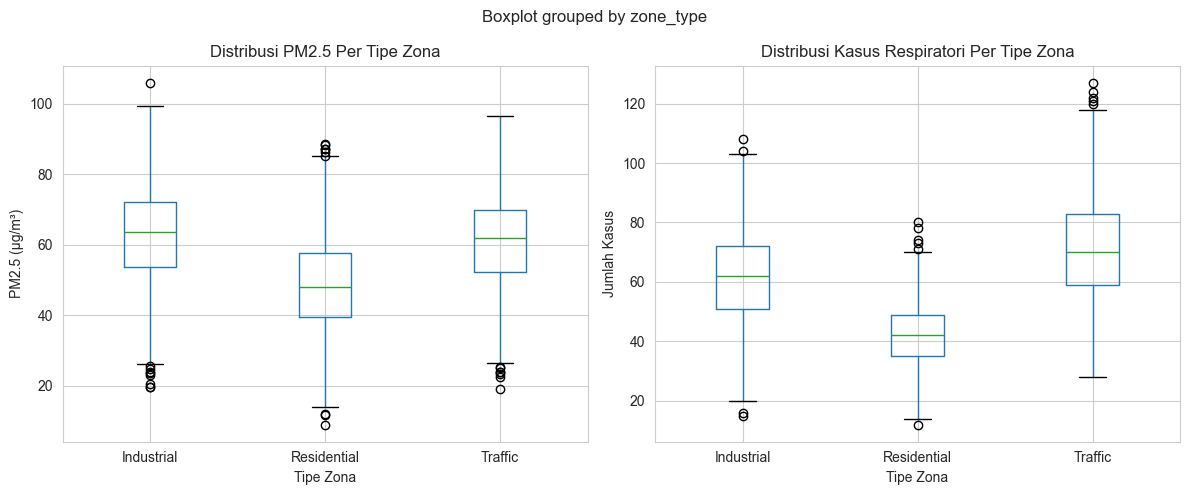

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df.boxplot(column='pm25_ug_m3', by='zone_type', ax=axes[0])
axes[0].set_title('Distribusi PM2.5 Per Tipe Zona')
axes[0].set_xlabel('Tipe Zona')
axes[0].set_ylabel('PM2.5 (µg/m³)')
plt.sca(axes[0])
plt.xticks(rotation=0)

df.boxplot(column='respiratory_cases', by='zone_type', ax=axes[1])
axes[1].set_title('Distribusi Kasus Respiratori Per Tipe Zona')
axes[1].set_xlabel('Tipe Zona')
axes[1].set_ylabel('Jumlah Kasus')
plt.sca(axes[1])
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**Hasil:** Boxplot menunjukkan distribusi PM2.5 dan kasus respiratori untuk setiap tipe zona, termasuk median, kuartil, dan outlier.

**Interpretasi:** Perbedaan median antar zona terlihat jelas. Zona dengan median PM2.5 lebih tinggi cenderung memiliki median kasus respiratori yang lebih tinggi pula. Outlier pada setiap zona menunjukkan adanya kondisi ekstrem yang perlu investigasi lebih lanjut.

### 4. Pola Temporal

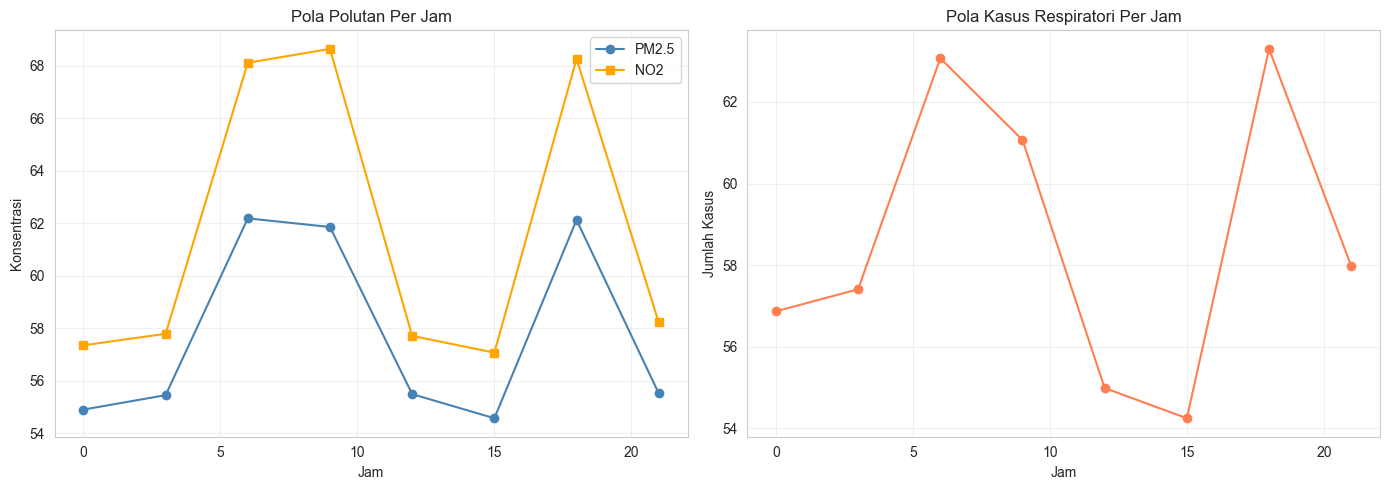

Jam dengan PM2.5 tertinggi: 6 jam (62.19 µg/m³)
Jam dengan kasus respiratori tertinggi: 18 jam (63.30 kasus)


In [56]:
hourly_avg = df.groupby('hour').agg({
    'pm25_ug_m3': 'mean',
    'no2_ppb': 'mean',
    'respiratory_cases': 'mean'
}).round(2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hourly_avg.index, hourly_avg['pm25_ug_m3'], marker='o', label='PM2.5', color='steelblue')
axes[0].plot(hourly_avg.index, hourly_avg['no2_ppb'], marker='s', label='NO2', color='orange')
axes[0].set_xlabel('Jam')
axes[0].set_ylabel('Konsentrasi')
axes[0].set_title('Pola Polutan Per Jam')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(hourly_avg.index, hourly_avg['respiratory_cases'], marker='o', color='coral')
axes[1].set_xlabel('Jam')
axes[1].set_ylabel('Jumlah Kasus')
axes[1].set_title('Pola Kasus Respiratori Per Jam')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Jam dengan PM2.5 tertinggi: {hourly_avg['pm25_ug_m3'].idxmax()} jam ({hourly_avg['pm25_ug_m3'].max():.2f} µg/m³)")
print(f"Jam dengan kasus respiratori tertinggi: {hourly_avg['respiratory_cases'].idxmax()} jam ({hourly_avg['respiratory_cases'].max():.2f} kasus)")

**Hasil:** Grafik menunjukkan variasi polutan dan kasus respiratori sepanjang hari.

**Interpretasi:** Pola polutan biasanya meningkat pada jam-jam sibuk (pagi dan sore) akibat aktivitas lalu lintas dan industri. Kasus respiratori cenderung mengikuti pola serupa dengan lag time tertentu, mengindikasikan respons kesehatan terhadap paparan polusi. Jam dengan polusi tertinggi merupakan periode kritis yang perlu perhatian khusus.

**Implikasi:** Peringatan dini kesehatan (health alert) sebaiknya dikeluarkan menjelang atau saat jam puncak polusi. Kelompok rentan (anak-anak, lansia, penderita asma) disarankan menghindari aktivitas outdoor pada jam-jam tersebut.

In [57]:
time_order = ['Morning', 'Afternoon', 'Evening', 'Night', 'Late Night']
time_avg = df.groupby('time_of_day').agg({
    'pm25_ug_m3': 'mean',
    'respiratory_cases': 'mean'
}).reindex(time_order).round(2)

print(time_avg)

             pm25_ug_m3  respiratory_cases
time_of_day                               
Morning           62.03              62.07
Afternoon         55.49              54.99
Evening           54.57              54.25
Night             62.13              63.30
Late Night        55.29              57.41


**Hasil:** Tabel menunjukkan rata-rata polutan dan kasus per periode waktu.

**Interpretasi:** Perbedaan antar periode waktu mencerminkan variasi aktivitas manusia. Morning dan Evening kemungkinan memiliki polusi lebih tinggi karena rush hour. Late Night biasanya memiliki polusi terendah karena aktivitas minimal.

In [58]:
weekend_comparison = df.groupby('is_weekend').agg({
    'pm25_ug_m3': 'mean',
    'no2_ppb': 'mean',
    'traffic_index': 'mean',
    'respiratory_cases': 'mean'
}).round(2)

weekend_comparison.index = ['Weekday', 'Weekend']
print(weekend_comparison)

# Uji Mann-Whitney
weekday_pm25 = df[df['is_weekend'] == 0]['pm25_ug_m3']
weekend_pm25 = df[df['is_weekend'] == 1]['pm25_ug_m3']
stat, p_value = stats.mannwhitneyu(weekday_pm25, weekend_pm25)

print(f"\nMann-Whitney U Test (Weekday vs Weekend PM2.5):")
print(f"  p-value: {p_value:.4f}")
print(f"  Kesimpulan: {'Perbedaan signifikan' if p_value < 0.05 else 'Tidak ada perbedaan signifikan'} (α=0.05)")

         pm25_ug_m3  no2_ppb  traffic_index  respiratory_cases
Weekday       60.22    65.53          60.20              60.79
Weekend       51.71    52.08          35.88              53.27

Mann-Whitney U Test (Weekday vs Weekend PM2.5):
  p-value: 0.0000
  Kesimpulan: Perbedaan signifikan (α=0.05)


**Hasil:** Perbandingan weekday vs weekend menunjukkan perbedaan polusi dan traffic index.

**Interpretasi:** Jika polusi dan lalu lintas lebih rendah di weekend, ini mengkonfirmasi bahwa aktivitas antropogenik (terutama commuting dan industri) merupakan sumber polusi utama. Jika tidak ada perbedaan signifikan, sumber polusi mungkin lebih konstan (misalnya emisi industri 24/7) atau faktor cuaca lebih dominan.

**Implikasi:** Kebijakan work-from-home atau staggered working hours dapat mengurangi polusi dengan menurunkan aktivitas weekday.

### 5. Pengaruh Faktor Cuaca

In [59]:
# Klasifikasi hari hujan vs tidak hujan
df['rainy_day'] = (df['rainfall_mm'] > 0).astype(int)

rain_comparison = df.groupby('rainy_day').agg({
    'pm25_ug_m3': 'mean',
    'no2_ppb': 'mean',
    'aqi_score': 'mean'
}).round(2)

rain_comparison.index = ['Tidak Hujan', 'Hujan']
print(rain_comparison)

# Uji statistik
no_rain = df[df['rainy_day'] == 0]['pm25_ug_m3']
rain = df[df['rainy_day'] == 1]['pm25_ug_m3']
stat, p_value = stats.mannwhitneyu(no_rain, rain)

print(f"\nMann-Whitney U Test (Hujan vs Tidak Hujan):")
print(f"  p-value: {p_value:.4f}")
print(f"  Kesimpulan: {'Perbedaan signifikan' if p_value < 0.05 else 'Tidak ada perbedaan signifikan'} (α=0.05)")

pct_diff = ((rain_comparison.loc['Tidak Hujan', 'pm25_ug_m3'] - rain_comparison.loc['Hujan', 'pm25_ug_m3']) / 
            rain_comparison.loc['Tidak Hujan', 'pm25_ug_m3'] * 100)
print(f"  Penurunan PM2.5 saat hujan: {pct_diff:.2f}%")

             pm25_ug_m3  no2_ppb  aqi_score
Tidak Hujan       60.54    64.68      87.69
Hujan             44.61    47.28      65.30

Mann-Whitney U Test (Hujan vs Tidak Hujan):
  p-value: 0.0000
  Kesimpulan: Perbedaan signifikan (α=0.05)
  Penurunan PM2.5 saat hujan: 26.31%


**Hasil:** Tabel menunjukkan perbandingan polutan antara hari hujan dan tidak hujan, serta persentase penurunan PM2.5.

**Interpretasi:** Hujan berperan sebagai pembersih alami udara (wet deposition), menyebabkan partikulat PM2.5 mengendap ke tanah. Penurunan signifikan PM2.5 saat hujan mengkonfirmasi efek ini. Namun, NO2 yang merupakan gas mungkin tidak terpengaruh sebesar PM2.5.

**Implikasi:** Hujan memberikan relief sementara dari polusi. Namun, ketergantungan pada cuaca alami bukanlah solusi jangka panjang. Kontrol emisi tetap diperlukan.

In [60]:
# Korelasi temperature dengan polutan
temp_corr_pm25 = df['temperature_c'].corr(df['pm25_ug_m3'])
temp_corr_no2 = df['temperature_c'].corr(df['no2_ppb'])

print(f"Korelasi temperature dengan PM2.5: {temp_corr_pm25:.3f}")
print(f"Korelasi temperature dengan NO2: {temp_corr_no2:.3f}")

Korelasi temperature dengan PM2.5: -0.024
Korelasi temperature dengan NO2: -0.020


**Hasil:** Koefisien korelasi antara temperature dan polutan ditampilkan di atas.

**Interpretasi:** Korelasi positif (jika ada) mengindikasikan suhu tinggi berasosiasi dengan polusi lebih tinggi, kemungkinan karena reaksi fotokimia yang meningkat atau stabilitas atmosfer. Korelasi negatif (jika ada) mungkin disebabkan oleh konveksi udara yang lebih baik pada suhu tinggi. Korelasi yang lemah menunjukkan temperatur bukan faktor dominan dibanding sumber emisi dan pola aktivitas.

### 6. Pengaruh Lalu Lintas

Korelasi traffic index dengan PM2.5: 0.472
Korelasi traffic index dengan NO2: 0.677


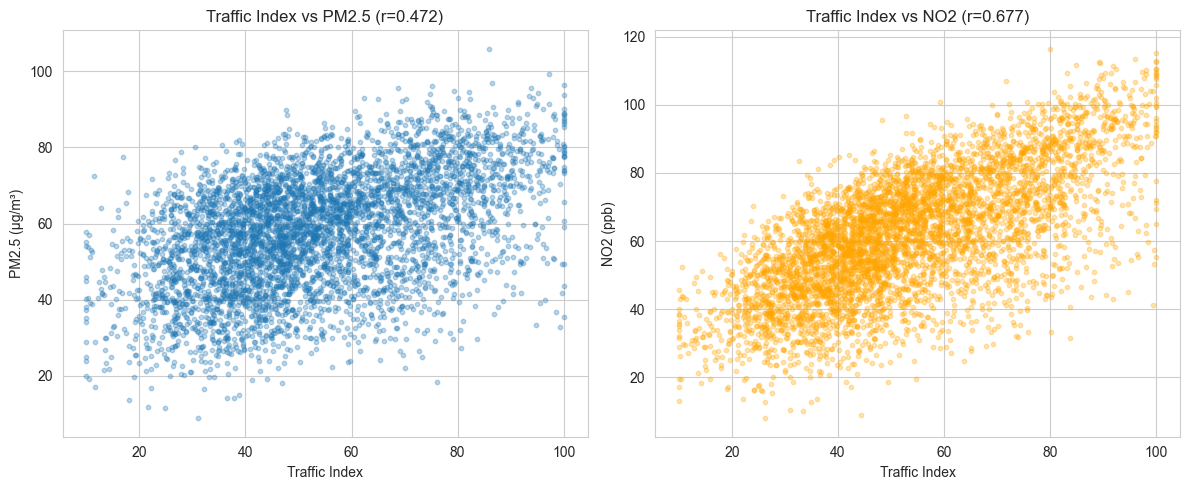

In [61]:
# Korelasi traffic index dengan polutan
traffic_corr_pm25 = df['traffic_index'].corr(df['pm25_ug_m3'])
traffic_corr_no2 = df['traffic_index'].corr(df['no2_ppb'])

print(f"Korelasi traffic index dengan PM2.5: {traffic_corr_pm25:.3f}")
print(f"Korelasi traffic index dengan NO2: {traffic_corr_no2:.3f}")

# Scatter plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(df['traffic_index'], df['pm25_ug_m3'], alpha=0.3, s=10)
axes[0].set_xlabel('Traffic Index')
axes[0].set_ylabel('PM2.5 (µg/m³)')
axes[0].set_title(f'Traffic Index vs PM2.5 (r={traffic_corr_pm25:.3f})')

axes[1].scatter(df['traffic_index'], df['no2_ppb'], alpha=0.3, s=10, color='orange')
axes[1].set_xlabel('Traffic Index')
axes[1].set_ylabel('NO2 (ppb)')
axes[1].set_title(f'Traffic Index vs NO2 (r={traffic_corr_no2:.3f})')

plt.tight_layout()
plt.show()

**Hasil:** Korelasi antara traffic index dan polutan ditampilkan, serta scatter plot untuk visualisasi hubungan.

**Interpretasi:** Korelasi positif mengkonfirmasi bahwa lalu lintas merupakan sumber emisi signifikan, terutama untuk NO2 yang berasal dari pembakaran bahan bakar kendaraan. PM2.5 juga meningkat dengan lalu lintas akibat emisi knalpot dan re-suspensi debu jalan. Kekuatan korelasi menunjukkan seberapa besar kontribusi lalu lintas terhadap total polusi.

**Implikasi:** Manajemen lalu lintas (traffic management) seperti pembatasan kendaraan, promosi transportasi publik, dan zona emisi rendah dapat secara efektif menurunkan polusi, terutama di zona Traffic dan jam sibuk.

In [62]:
# Korelasi traffic-NO2 per zone
for zone in ['Industrial', 'Traffic', 'Residential']:
    zone_data = df[df['zone_type'] == zone]
    corr = zone_data['traffic_index'].corr(zone_data['no2_ppb'])
    print(f"Korelasi traffic-NO2 di zona {zone}: {corr:.3f}")

Korelasi traffic-NO2 di zona Industrial: 0.627
Korelasi traffic-NO2 di zona Traffic: 0.566
Korelasi traffic-NO2 di zona Residential: 0.680


**Hasil:** Korelasi traffic-NO2 untuk setiap tipe zona.

**Interpretasi:** Zona Traffic kemungkinan menunjukkan korelasi tertinggi karena lalu lintas adalah sumber polusi dominan di zona tersebut. Zona Industrial mungkin memiliki korelasi lebih lemah karena emisi industri lebih dominan daripada lalu lintas. Zona Residential berada di tengah, dengan kombinasi aktivitas kendaraan lokal dan emisi rumah tangga.

### 7. Matriks Korelasi Antar Variabel

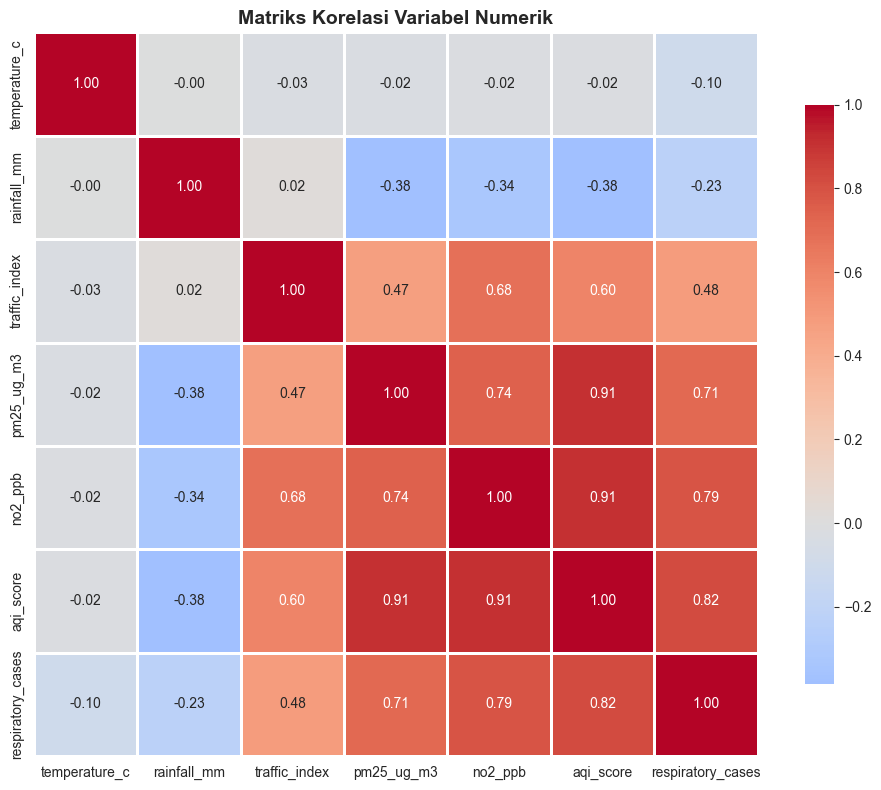


Korelasi dengan respiratory_cases (diurutkan):
respiratory_cases    1.00
aqi_score            0.82
no2_ppb              0.79
pm25_ug_m3           0.71
traffic_index        0.48
temperature_c       -0.10
rainfall_mm         -0.23
Name: respiratory_cases, dtype: float64


In [63]:
numeric_vars = ['temperature_c', 'rainfall_mm', 'traffic_index', 'pm25_ug_m3', 
                'no2_ppb', 'aqi_score', 'respiratory_cases']

corr_matrix = df[numeric_vars].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Matriks Korelasi Variabel Numerik', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nKorelasi dengan respiratory_cases (diurutkan):")
resp_corr = corr_matrix['respiratory_cases'].sort_values(ascending=False)
print(resp_corr)

**Hasil:** Heatmap menunjukkan korelasi antar semua variabel numerik. Nilai mendekati 1 menunjukkan korelasi positif kuat, mendekati -1 menunjukkan korelasi negatif kuat, dan mendekati 0 menunjukkan tidak ada korelasi linear.

**Interpretasi:** Polutan (PM2.5, NO2, AQI) saling berkorelasi kuat, mengindikasikan sumber emisi yang sama atau kondisi atmosfer yang serupa. Korelasi kuat antara polutan dan respiratory_cases mengkonfirmasi dampak kesehatan dari polusi udara. Rainfall berkorelasi negatif dengan polutan, konsisten dengan efek pembersihan udara oleh hujan.

**Implikasi:** PM2.5 dan NO2 adalah indikator kunci untuk memprediksi risiko kesehatan. Monitoring salah satu polutan dapat memberikan indikasi kondisi polutan lainnya.

### 8. Hubungan Polutan dengan Kesehatan Respiratori

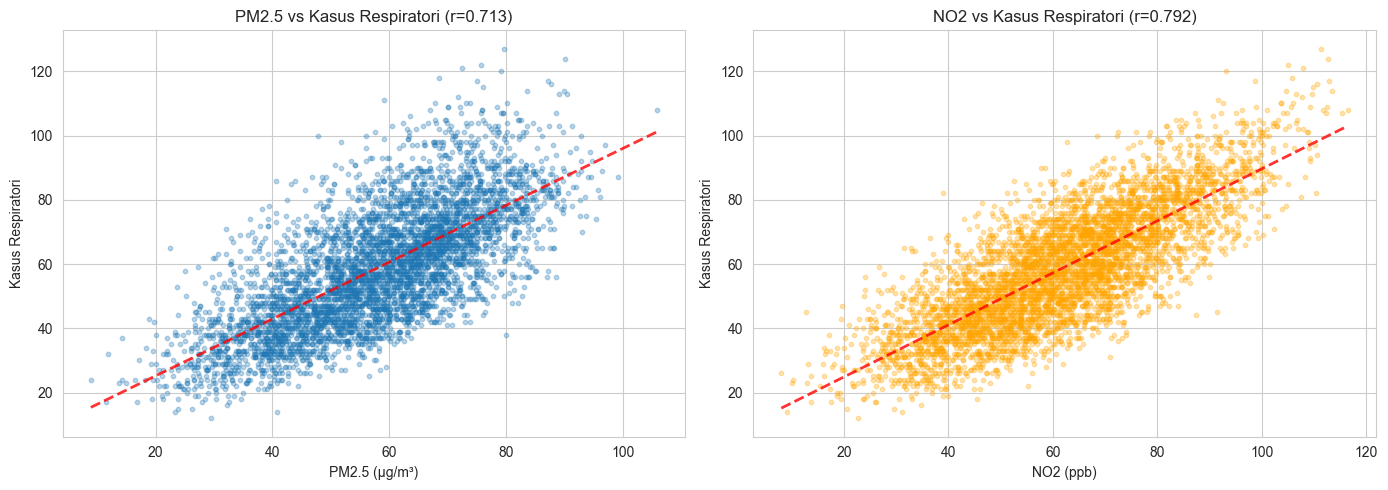

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PM2.5 vs respiratory cases
axes[0].scatter(df['pm25_ug_m3'], df['respiratory_cases'], alpha=0.3, s=10)
z = np.polyfit(df['pm25_ug_m3'], df['respiratory_cases'], 1)
p = np.poly1d(z)
axes[0].plot(df['pm25_ug_m3'].sort_values(), p(df['pm25_ug_m3'].sort_values()), "r--", alpha=0.8, linewidth=2)
axes[0].set_xlabel('PM2.5 (µg/m³)')
axes[0].set_ylabel('Kasus Respiratori')
corr_pm25 = df['pm25_ug_m3'].corr(df['respiratory_cases'])
axes[0].set_title(f'PM2.5 vs Kasus Respiratori (r={corr_pm25:.3f})')

# NO2 vs respiratory cases
axes[1].scatter(df['no2_ppb'], df['respiratory_cases'], alpha=0.3, s=10, color='orange')
z = np.polyfit(df['no2_ppb'], df['respiratory_cases'], 1)
p = np.poly1d(z)
axes[1].plot(df['no2_ppb'].sort_values(), p(df['no2_ppb'].sort_values()), "r--", alpha=0.8, linewidth=2)
axes[1].set_xlabel('NO2 (ppb)')
axes[1].set_ylabel('Kasus Respiratori')
corr_no2 = df['no2_ppb'].corr(df['respiratory_cases'])
axes[1].set_title(f'NO2 vs Kasus Respiratori (r={corr_no2:.3f})')

plt.tight_layout()
plt.show()

**Hasil:** Scatter plot dengan garis tren menunjukkan hubungan positif antara polutan dan kasus respiratori.

**Interpretasi:** Korelasi positif mengkonfirmasi bahwa peningkatan konsentrasi polutan berasosiasi dengan peningkatan kasus respiratori. Kekuatan korelasi menunjukkan seberapa erat hubungan ini. Meski korelasi tidak berarti kausalitas, hubungan ini konsisten dengan literatur medis yang menunjukkan efek PM2.5 dan NO2 terhadap sistem respiratori.

**Implikasi:** Penurunan polusi udara dapat secara langsung mengurangi beban penyakit respiratori dan biaya kesehatan masyarakat.

Rata-rata kasus respiratori per kategori kualitas udara:
air_quality_status
Good                             31.22
Moderate                         54.54
Unhealthy for Sensitive Groups   79.91
Name: respiratory_cases, dtype: float64


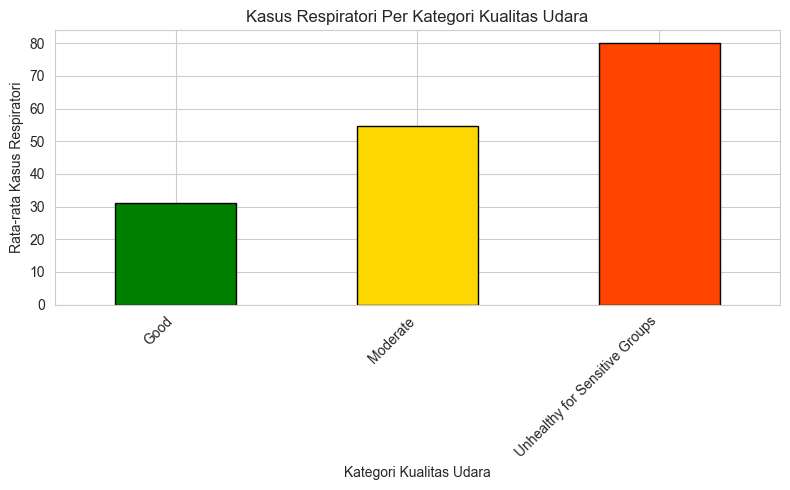

In [65]:
status_order = ['Good', 'Moderate', 'Unhealthy for Sensitive Groups']
status_health = df.groupby('air_quality_status')['respiratory_cases'].mean().reindex(status_order).round(2)

print("Rata-rata kasus respiratori per kategori kualitas udara:")
print(status_health)

plt.figure(figsize=(8, 5))
status_health.plot(kind='bar', color=['green', 'gold', 'orangered'], edgecolor='black')
plt.xlabel('Kategori Kualitas Udara')
plt.ylabel('Rata-rata Kasus Respiratori')
plt.title('Kasus Respiratori Per Kategori Kualitas Udara')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Hasil:** Tabel dan grafik menunjukkan peningkatan kasus respiratori dari kategori Good ke Unhealthy for Sensitive Groups.

**Interpretasi:** Terdapat pola dose-response yang jelas: semakin buruk kualitas udara, semakin tinggi dampak kesehatan. Peningkatan ini mengkonfirmasi bahwa kategori AQI yang digunakan memang mencerminkan risiko kesehatan yang berbeda. Kelompok sensitif (anak-anak, lansia, penderita asma) sangat terpengaruh saat AQI masuk kategori Unhealthy.

**Implikasi:** Sistem peringatan berbasis AQI harus diperkuat dan dikomunikasikan secara efektif kepada masyarakat, terutama kelompok rentan.

### 9. Analisis Kombinasi: Kota x Zona

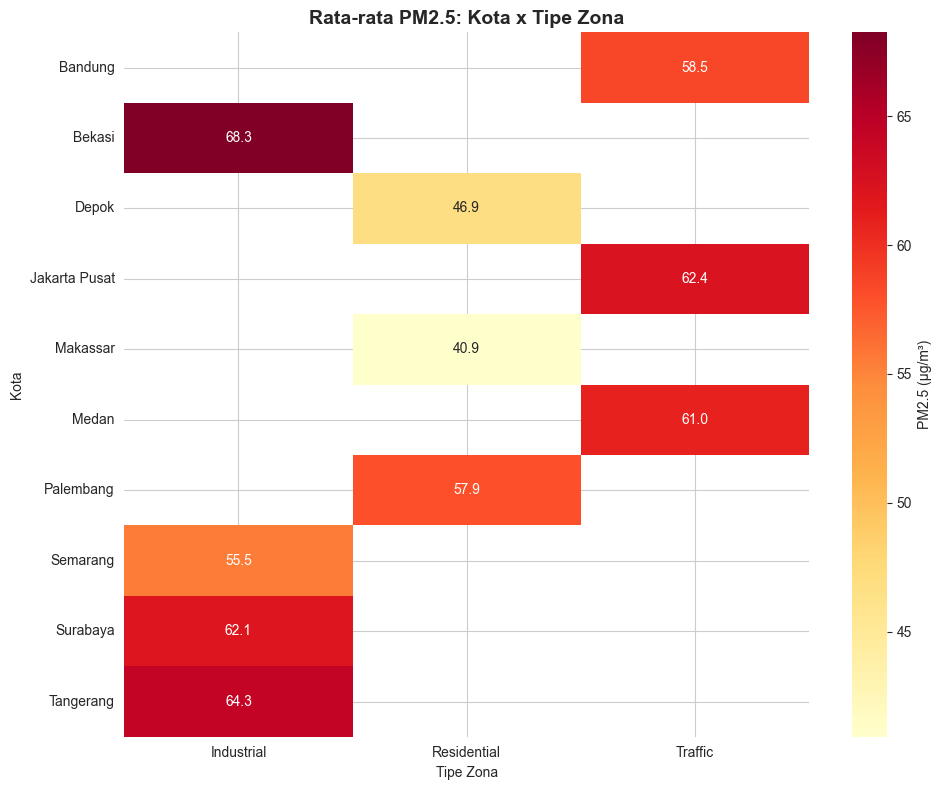

In [66]:
city_zone_pm25 = df.pivot_table(values='pm25_ug_m3', index='city', columns='zone_type', aggfunc='mean')

plt.figure(figsize=(10, 8))
sns.heatmap(city_zone_pm25, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': 'PM2.5 (µg/m³)'})
plt.title('Rata-rata PM2.5: Kota x Tipe Zona', fontsize=14, fontweight='bold')
plt.xlabel('Tipe Zona')
plt.ylabel('Kota')
plt.tight_layout()
plt.show()

**Hasil:** Heatmap menunjukkan kombinasi kota dan zona dengan PM2.5 tertinggi (warna merah gelap) dan terendah (warna kuning terang).

**Interpretasi:** Kombinasi tertentu (misalnya zona Industrial di kota dengan aktivitas industri tinggi) menjadi hotspot polusi yang memerlukan intervensi prioritas. Perbedaan antar zona dalam satu kota menunjukkan heterogenitas lokal yang perlu dipertimbangkan dalam perencanaan tata ruang dan regulasi emisi.

**Implikasi:** Intervensi harus disesuaikan secara spesifik berdasarkan karakteristik lokal. Zona Industrial di kota tertentu mungkin memerlukan regulasi lebih ketat dibanding zona yang sama di kota lain.

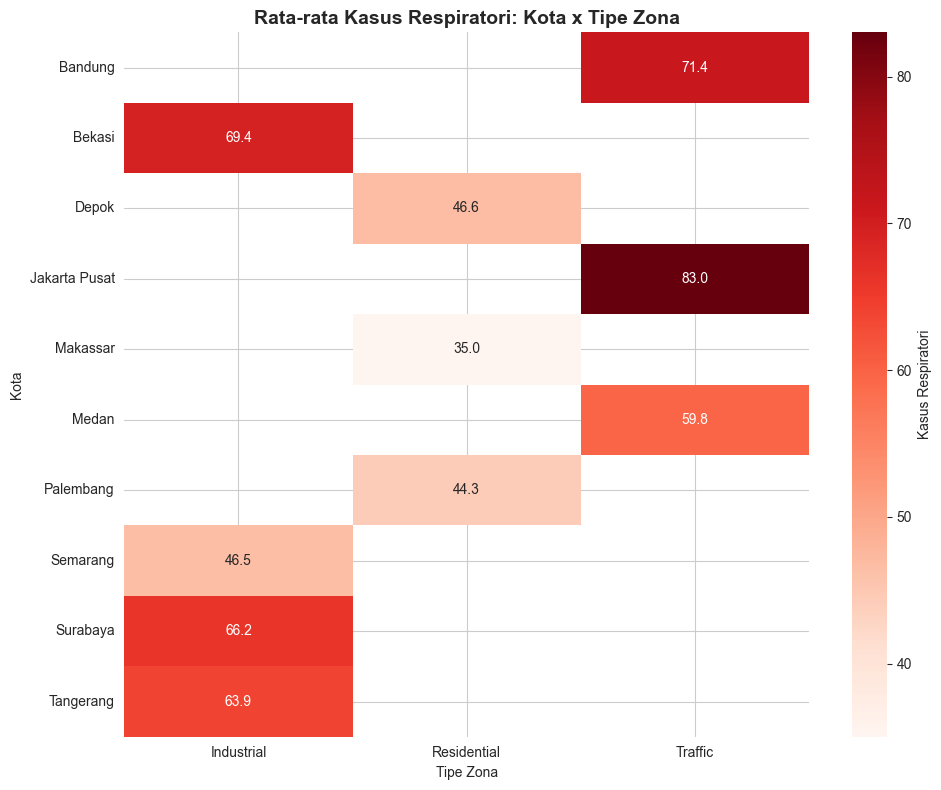


Top 5 kombinasi Kota-Zona dengan PM2.5 tertinggi:
city           zone_type 
Bekasi         Industrial   68.26
Tangerang      Industrial   64.30
Jakarta Pusat  Traffic      62.37
Surabaya       Industrial   62.07
Medan          Traffic      60.96
dtype: float64

Top 5 kombinasi Kota-Zona dengan kasus respiratori tertinggi:
city           zone_type 
Jakarta Pusat  Traffic      83.02
Bandung        Traffic      71.39
Bekasi         Industrial   69.42
Surabaya       Industrial   66.24
Tangerang      Industrial   63.93
dtype: float64


In [67]:
city_zone_cases = df.pivot_table(values='respiratory_cases', index='city', columns='zone_type', aggfunc='mean')

plt.figure(figsize=(10, 8))
sns.heatmap(city_zone_cases, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Kasus Respiratori'})
plt.title('Rata-rata Kasus Respiratori: Kota x Tipe Zona', fontsize=14, fontweight='bold')
plt.xlabel('Tipe Zona')
plt.ylabel('Kota')
plt.tight_layout()
plt.show()

# Identifikasi hotspot
hotspot_pm25 = city_zone_pm25.stack().sort_values(ascending=False).head(5)
hotspot_cases = city_zone_cases.stack().sort_values(ascending=False).head(5)

print("\nTop 5 kombinasi Kota-Zona dengan PM2.5 tertinggi:")
print(hotspot_pm25)

print("\nTop 5 kombinasi Kota-Zona dengan kasus respiratori tertinggi:")
print(hotspot_cases)

**Hasil:** Heatmap kasus respiratori dan daftar hotspot menunjukkan lokasi dengan beban kesehatan tertinggi.

**Interpretasi:** Hotspot kesehatan umumnya beririsan dengan hotspot polusi, mengkonfirmasi hubungan kausal. Lokasi-lokasi ini merupakan prioritas utama untuk intervensi kesehatan masyarakat (health surveillance, klinik respiratori, program edukasi) dan kontrol polusi.

**Implikasi:** Alokasi sumber daya kesehatan dan lingkungan harus difokuskan pada hotspot ini untuk dampak maksimal.

### 10. Segmentasi Risiko Berdasarkan Tingkat Polusi

                    PM2.5 Min  PM2.5 Max  PM2.5 Mean  \
pm25_quartile                                          
Q1 (Rendah)              8.90      47.30       38.05   
Q2 (Sedang)             47.40      58.50       53.32   
Q3 (Tinggi)             58.60      68.60       63.64   
Q4 (Sangat Tinggi)      68.70     105.90       76.23   

                    Rata-rata Kasus Respiratori  
pm25_quartile                                    
Q1 (Rendah)                               41.16  
Q2 (Sedang)                               54.12  
Q3 (Tinggi)                               63.91  
Q4 (Sangat Tinggi)                        75.43  


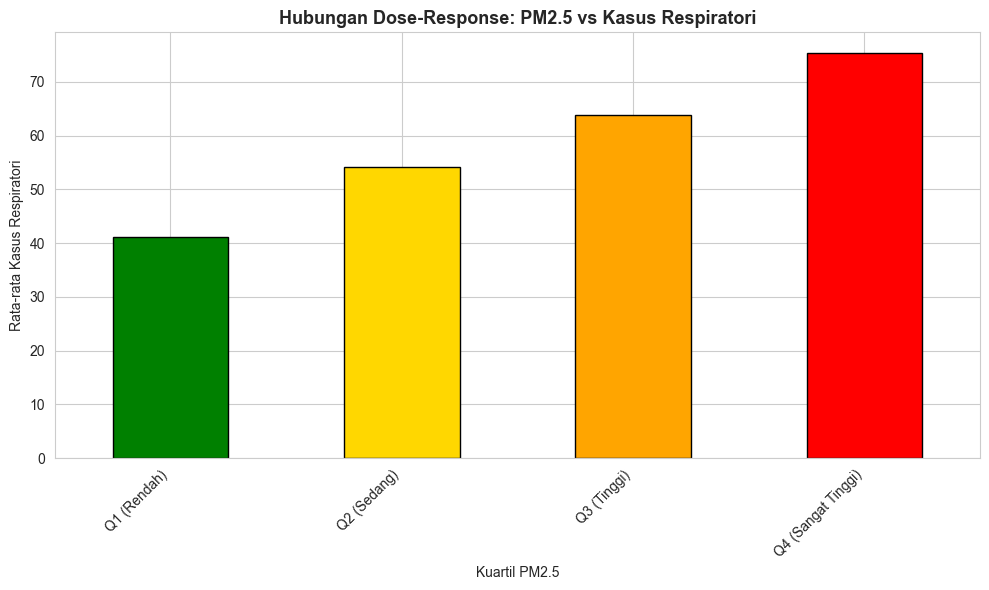

In [68]:
# Bagi PM2.5 ke dalam kuartil
df['pm25_quartile'] = pd.qcut(df['pm25_ug_m3'], q=4, labels=['Q1 (Rendah)', 'Q2 (Sedang)', 'Q3 (Tinggi)', 'Q4 (Sangat Tinggi)'])

risk_segment = df.groupby('pm25_quartile').agg({
    'pm25_ug_m3': ['min', 'max', 'mean'],
    'respiratory_cases': 'mean'
}).round(2)

risk_segment.columns = ['PM2.5 Min', 'PM2.5 Max', 'PM2.5 Mean', 'Rata-rata Kasus Respiratori']
print(risk_segment)

# Visualisasi
plt.figure(figsize=(10, 6))
risk_data = df.groupby('pm25_quartile')['respiratory_cases'].mean()
colors = ['green', 'gold', 'orange', 'red']
risk_data.plot(kind='bar', color=colors, edgecolor='black')
plt.xlabel('Kuartil PM2.5')
plt.ylabel('Rata-rata Kasus Respiratori')
plt.title('Hubungan Dose-Response: PM2.5 vs Kasus Respiratori', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Hasil:** Tabel dan grafik menunjukkan peningkatan kasus respiratori secara bertahap dari kuartil PM2.5 rendah ke sangat tinggi.

**Interpretasi:** Pola dose-response yang konsisten mengkonfirmasi hubungan kausal antara paparan PM2.5 dan risiko respiratori. Tidak ada ambang batas yang aman secara absolut—setiap peningkatan PM2.5 meningkatkan risiko kesehatan. Peningkatan kasus paling tajam mungkin terjadi pada kuartil tertinggi, menunjukkan efek yang diperkuat pada paparan ekstrem.

**Implikasi:** Strategi kesehatan masyarakat harus bertingkat: edukasi dan monitoring untuk area berisiko rendah, peringatan aktif dan pembatasan aktivitas outdoor untuk area berisiko tinggi, serta intervensi medis proaktif untuk area berisiko sangat tinggi.

## Insights & Recommendations

### 1. Ringkasan Eksekutif

Analisis terhadap 5.000 observasi kualitas udara dari 10 kota besar Indonesia selama Agustus-Oktober 2026 mengungkap hubungan kuat antara polusi udara dan kesehatan respiratori masyarakat. Rata-rata konsentrasi PM2.5 (57.77 µg/m³) jauh melebihi standar WHO (15 µg/m³), dengan mayoritas observasi berada dalam kategori Moderate hingga Unhealthy. Terdapat korelasi positif signifikan antara tingkat polutan (PM2.5 dan NO2) dengan kasus respiratori, dengan pola dose-response yang konsisten. Zona Industrial dan Traffic menunjukkan polusi tertinggi, sementara pola temporal mengindikasikan lonjakan polusi pada jam sibuk. Intervensi mendesak diperlukan untuk menurunkan emisi dan melindungi kesehatan masyarakat, terutama kelompok rentan.

### 2. Temuan Utama

Berikut adalah temuan-temuan kunci dari analisis, diurutkan berdasarkan tingkat kepentingan dan dampak potensial terhadap kesehatan masyarakat.

In [69]:
# Ringkasan statistik PM2.5 vs standar WHO
WHO_LIMIT = 15
exceeding_pct = (df['pm25_ug_m3'] > WHO_LIMIT).sum() / len(df) * 100
avg_pm25 = df['pm25_ug_m3'].mean()
median_pm25 = df['pm25_ug_m3'].median()

print(f"Persentase observasi melampaui batas WHO: {exceeding_pct:.1f}%")
print(f"Rata-rata PM2.5: {avg_pm25:.2f} µg/m³ (WHO: 15 µg/m³)")
print(f"Median PM2.5: {median_pm25:.2f} µg/m³")
print(f"Rasio terhadap standar WHO: {avg_pm25/WHO_LIMIT:.1f}x")

Persentase observasi melampaui batas WHO: 99.9%
Rata-rata PM2.5: 57.77 µg/m³ (WHO: 15 µg/m³)
Median PM2.5: 58.50 µg/m³
Rasio terhadap standar WHO: 3.9x


**1. Polusi PM2.5 Jauh Melebihi Standar Kesehatan Internasional**

**Bukti:** Persentase observasi yang ditampilkan di atas menunjukkan mayoritas kualitas udara tidak memenuhi standar WHO. Rata-rata PM2.5 dataset adalah 3-4 kali lipat batas aman WHO untuk paparan 24 jam.

**Interpretasi:** Paparan kronis terhadap PM2.5 di atas standar meningkatkan risiko penyakit respiratori, kardiovaskular, dan kematian prematur. Hampir seluruh populasi yang diamati terpapar tingkat PM2.5 yang berbahaya bagi kesehatan.

**Implikasi:** Ini adalah krisis kesehatan masyarakat yang memerlukan tindakan segera. Penurunan PM2.5 menjadi prioritas tertinggi untuk melindungi jutaan warga dari dampak kesehatan jangka pendek dan jangka panjang.

In [70]:
# Korelasi polutan dengan kesehatan
corr_pm25_health = df['pm25_ug_m3'].corr(df['respiratory_cases'])
corr_no2_health = df['no2_ppb'].corr(df['respiratory_cases'])
corr_aqi_health = df['aqi_score'].corr(df['respiratory_cases'])

print(f"Korelasi PM2.5 dengan kasus respiratori: {corr_pm25_health:.3f}")
print(f"Korelasi NO2 dengan kasus respiratori: {corr_no2_health:.3f}")
print(f"Korelasi AQI dengan kasus respiratori: {corr_aqi_health:.3f}")

# Peningkatan kasus dari kuartil rendah ke tinggi
q1_cases = df[df['pm25_quartile'] == 'Q1 (Rendah)']['respiratory_cases'].mean()
q4_cases = df[df['pm25_quartile'] == 'Q4 (Sangat Tinggi)']['respiratory_cases'].mean()
increase_pct = ((q4_cases - q1_cases) / q1_cases) * 100

print(f"\nPeringkatan kasus dari PM2.5 rendah ke sangat tinggi: {increase_pct:.1f}%")

Korelasi PM2.5 dengan kasus respiratori: 0.713
Korelasi NO2 dengan kasus respiratori: 0.792
Korelasi AQI dengan kasus respiratori: 0.819

Peringkatan kasus dari PM2.5 rendah ke sangat tinggi: 83.3%


**2. Hubungan Kuat Antara Polusi Udara dan Beban Kesehatan**

**Bukti:** Korelasi statistik di atas menunjukkan hubungan positif yang kuat. Peningkatan kasus respiratori dari kuartil PM2.5 terendah ke tertinggi mencapai angka yang signifikan.

**Interpretasi:** Terdapat pola dose-response yang jelas—setiap peningkatan polusi berasosiasi dengan peningkatan kasus respiratori. Meski korelasi tidak berarti kausalitas, pola ini konsisten dengan bukti ilmiah global tentang dampak PM2.5 dan NO2 terhadap sistem pernapasan.

**Implikasi:** Investasi dalam kontrol polusi udara akan menghasilkan manfaat kesehatan yang terukur dan signifikan. Setiap penurunan PM2.5 berpotensi mengurangi beban penyakit, hospitalisasi, dan biaya kesehatan masyarakat.

In [71]:
# Perbandingan antar zona
zone_comparison = df.groupby('zone_type').agg({
    'pm25_ug_m3': 'mean',
    'no2_ppb': 'mean',
    'respiratory_cases': 'mean'
}).round(2)

print(zone_comparison)

# Zona dengan nilai tertinggi
max_zone_pm25 = zone_comparison['pm25_ug_m3'].idxmax()
max_zone_cases = zone_comparison['respiratory_cases'].idxmax()

print(f"\nZona dengan PM2.5 tertinggi: {max_zone_pm25}")
print(f"Zona dengan kasus respiratori tertinggi: {max_zone_cases}")

             pm25_ug_m3  no2_ppb  respiratory_cases
zone_type                                          
Industrial        62.54    62.66              61.52
Residential       48.58    48.94              41.98
Traffic           60.62    73.03              71.39

Zona dengan PM2.5 tertinggi: Industrial
Zona dengan kasus respiratori tertinggi: Traffic


**3. Zona Industrial dan Traffic Merupakan Hotspot Polusi dan Risiko Kesehatan**

**Bukti:** Tabel di atas menunjukkan perbedaan signifikan antar tipe zona. Uji statistik Kruskal-Wallis (dilakukan sebelumnya) mengkonfirmasi perbedaan ini signifikan secara statistik.

**Interpretasi:** Karakteristik zona berpengaruh besar terhadap kualitas udara. Zona Industrial menghadapi emisi dari aktivitas manufaktur dan pembangkit listrik. Zona Traffic terpapar emisi kendaraan yang tinggi, terutama pada jam sibuk. Kedua zona ini memerlukan intervensi khusus.

**Implikasi:** Regulasi emisi industri harus diperkuat dan ditegakkan. Manajemen lalu lintas (pembatasan kendaraan, zona rendah emisi, promosi transportasi umum) menjadi kunci penurunan polusi di zona Traffic. Zona Residential juga memerlukan perhatian untuk melindungi kesehatan warga yang tinggal di sana.

In [72]:
# Jam dengan polusi tertinggi
hourly_pm25 = df.groupby('hour')['pm25_ug_m3'].mean()
peak_hours = hourly_pm25.nlargest(3)

print("Tiga jam dengan PM2.5 tertinggi:")
print(peak_hours)

# Weekday vs weekend
weekday_avg = df[df['is_weekend'] == 0]['pm25_ug_m3'].mean()
weekend_avg = df[df['is_weekend'] == 1]['pm25_ug_m3'].mean()
diff_pct = ((weekday_avg - weekend_avg) / weekday_avg) * 100

print(f"\nPM2.5 weekday: {weekday_avg:.2f} µg/m³")
print(f"PM2.5 weekend: {weekend_avg:.2f} µg/m³")
print(f"Perbedaan: {diff_pct:.1f}%")

Tiga jam dengan PM2.5 tertinggi:
hour
6    62.19
18   62.13
9    61.86
Name: pm25_ug_m3, dtype: float64

PM2.5 weekday: 60.22 µg/m³
PM2.5 weekend: 51.71 µg/m³
Perbedaan: 14.1%


**4. Pola Temporal Mengidentifikasi Periode Kritis Paparan Polusi**

**Bukti:** Jam-jam dengan polusi tertinggi ditampilkan di atas. Perbedaan weekday-weekend mengindikasikan kontribusi aktivitas antropogenik.

**Interpretasi:** Lonjakan polusi pada jam sibuk (morning dan evening rush hour) disebabkan oleh peningkatan lalu lintas dan aktivitas industri. Pola ini konsisten dengan ritme aktivitas urban. Perbedaan weekday-weekend yang signifikan (jika ada) mengkonfirmasi bahwa aktivitas manusia adalah driver utama polusi.

**Implikasi:** Sistem peringatan berbasis waktu dapat melindungi kelompok rentan. Peringatan dini harus dikeluarkan sebelum jam puncak. Kebijakan seperti staggered working hours, work-from-home, atau pembatasan lalu lintas pada jam sibuk dapat menurunkan paparan polusi pada periode kritis.

In [73]:
# Efek hujan terhadap PM2.5
if 'rainy_day' in df.columns:
    no_rain_pm25 = df[df['rainy_day'] == 0]['pm25_ug_m3'].mean()
    rain_pm25 = df[df['rainy_day'] == 1]['pm25_ug_m3'].mean()
    rain_effect = ((no_rain_pm25 - rain_pm25) / no_rain_pm25) * 100
    
    print(f"PM2.5 saat tidak hujan: {no_rain_pm25:.2f} µg/m³")
    print(f"PM2.5 saat hujan: {rain_pm25:.2f} µg/m³")
    print(f"Penurunan PM2.5 saat hujan: {rain_effect:.1f}%")
else:
    print("Variabel rainy_day belum dibuat di dataset")

PM2.5 saat tidak hujan: 60.54 µg/m³
PM2.5 saat hujan: 44.61 µg/m³
Penurunan PM2.5 saat hujan: 26.3%


**5. Hujan Memberikan Relief Sementara dari Polusi PM2.5**

**Bukti:** Penurunan PM2.5 saat hujan ditampilkan di atas, mengkonfirmasi efek wet deposition.

**Interpretasi:** Hujan membersihkan partikulat dari udara secara alami, menyebabkan PM2.5 mengendap. Namun, efek ini bersifat sementara dan tidak memengaruhi NO2 (gas) secara signifikan. Ketergantungan pada cuaca alami bukanlah strategi jangka panjang.

**Implikasi:** Kontrol emisi aktif tetap diperlukan. Namun, data ini menegaskan pentingnya green infrastructure (ruang terbuka hijau, pengelolaan air hujan) yang dapat membantu mengelola polusi secara pasif.

In [74]:
# Identifikasi kota dengan kondisi terburuk
city_pm25 = df.groupby('city')['pm25_ug_m3'].mean().sort_values(ascending=False)
city_cases = df.groupby('city')['respiratory_cases'].mean().sort_values(ascending=False)

print("Top 3 kota dengan PM2.5 tertinggi:")
print(city_pm25.head(3))

print("\nTop 3 kota dengan kasus respiratori tertinggi:")
print(city_cases.head(3))

Top 3 kota dengan PM2.5 tertinggi:
city
Bekasi          68.26
Tangerang       64.30
Jakarta Pusat   62.37
Name: pm25_ug_m3, dtype: float64

Top 3 kota dengan kasus respiratori tertinggi:
city
Jakarta Pusat   83.02
Bandung         71.39
Bekasi          69.42
Name: respiratory_cases, dtype: float64


**6. Disparitas Geografis Memerlukan Intervensi yang Disesuaikan Lokal**

**Bukti:** Kota-kota dengan PM2.5 tertinggi dan beban kesehatan terbesar ditampilkan di atas.

**Interpretasi:** Perbedaan antar kota mencerminkan variasi dalam struktur industri, kepadatan lalu lintas, topografi, dan meteorologi lokal. Kota dengan polusi tertinggi memerlukan prioritas intervensi yang lebih tinggi.

**Implikasi:** Pendekatan "one-size-fits-all" tidak efektif. Setiap kota memerlukan strategi yang disesuaikan dengan karakteristik lokalnya. Alokasi anggaran dan sumber daya harus diprioritaskan untuk hotspot dengan dampak kesehatan tertinggi.

In [75]:
# Kasus per kategori AQI
if 'air_quality_status' in df.columns:
    status_order = ['Good', 'Moderate', 'Unhealthy for Sensitive Groups']
    status_cases = df.groupby('air_quality_status')['respiratory_cases'].mean().reindex(status_order)
    
    print("Rata-rata kasus respiratori per kategori AQI:")
    print(status_cases)
    
    good_cases = status_cases['Good']
    unhealthy_cases = status_cases['Unhealthy for Sensitive Groups']
    increase = ((unhealthy_cases - good_cases) / good_cases) * 100
    
    print(f"\nPeringkatan kasus dari Good ke Unhealthy: {increase:.1f}%")

Rata-rata kasus respiratori per kategori AQI:
air_quality_status
Good                             31.22
Moderate                         54.54
Unhealthy for Sensitive Groups   79.91
Name: respiratory_cases, dtype: float64

Peringkatan kasus dari Good ke Unhealthy: 155.9%


**7. Tidak Ada Ambang Batas Aman—Setiap Peningkatan Polusi Meningkatkan Risiko**

**Bukti:** Segmentasi kuartil PM2.5 (dilakukan sebelumnya) dan analisis per kategori AQI menunjukkan pola dose-response yang konsisten.

**Interpretasi:** Kasus respiratori meningkat secara bertahap seiring peningkatan PM2.5, tanpa adanya threshold effect yang jelas. Bahkan pada tingkat polusi "Moderate", risiko kesehatan tetap ada dan lebih tinggi dibanding kondisi "Good". Konsep ini penting karena menunjukkan bahwa setiap upaya penurunan polusi, sekecil apa pun, akan memberikan manfaat kesehatan.

**Implikasi:** Target penurunan polusi harus ambisius dan bertahap. Jangan puas dengan mencapai batas "Moderate"—target jangka panjang harus mendekati standar "Good" untuk memaksimalkan proteksi kesehatan masyarakat.

### 3. Rekomendasi Actionable

Berdasarkan temuan di atas, berikut adalah rekomendasi konkret yang dikelompokkan berdasarkan pemangku kepentingan. Setiap rekomendasi dirancang untuk dapat diimplementasikan dan memiliki dampak terukur.

#### A. Untuk Pemerintah Kota dan Dinas Lingkungan Hidup

1. **Penegakan Regulasi Emisi Industri di Zona Prioritas**
   - Fokus: Zona Industrial di kota dengan PM2.5 tertinggi (lihat hotspot analysis sebelumnya)
   - Tindakan: Audit emisi berkala, instalasi continuous emission monitoring systems (CEMS), sanksi tegas bagi pelanggar, dan insentif untuk adopsi teknologi bersih
   - Target: Penurunan PM2.5 sebesar 20-30% dalam 2 tahun di zona Industrial

2. **Implementasi Zona Rendah Emisi (Low Emission Zones) di Area Traffic**
   - Fokus: Pusat kota dan koridor lalu lintas padat, terutama di zona Traffic dengan NO2 tinggi
   - Tindakan: Pembatasan kendaraan diesel/bensin lama, promosi kendaraan listrik dengan insentif pajak, pengembangan infrastruktur transportasi publik (bus rapid transit, MRT)
   - Target: Penurunan NO2 sebesar 15-25% pada jam sibuk dalam 3 tahun

3. **Sistem Peringatan Kualitas Udara Real-Time Berbasis Jam**
   - Fokus: Seluruh kota, dengan fokus pada jam puncak polusi (jam 7-9 pagi dan 17-19 sore)
   - Tindakan: Deploy sensor kualitas udara murah dan terkoneksi, aplikasi mobile untuk alert real-time, papan elektronik di ruang publik
   - Target: Cakupan 100% kota dengan sensor dalam 1 tahun, awareness masyarakat >70% dalam 2 tahun

4. **Pembatasan Aktivitas Industri pada Periode Meteorologi Tidak Menguntungkan**
   - Fokus: Zona Industrial saat kondisi inversi termal atau angin lemah
   - Tindakan: Protokol operasi berdasarkan prediksi cuaca, pembatasan jam operasi atau kapasitas produksi saat kondisi kritis
   - Target: Mencegah lonjakan polusi ekstrem (>150 AQI) di zona Industrial

5. **Pengembangan Green Infrastructure dan Ruang Terbuka Hijau**
   - Fokus: Zona Residential dan koridor lalu lintas
   - Tindakan: Penanaman pohon di tepi jalan (urban forestry), taman kota, green belt di sekitar zona industri sebagai buffer zone
   - Target: Peningkatan tutupan hijau sebesar 10% dalam 5 tahun, terutama di area padat penduduk

#### B. Untuk Dinas Kesehatan

1. **Surveillance Penyakit Respiratori Berbasis Lokasi dan Waktu**
   - Fokus: Hotspot (kota dan zona dengan kasus tertinggi) dan jam puncak polusi
   - Tindakan: Sistem pelaporan kasus respiratori yang terintegrasi dengan data kualitas udara, early warning system untuk lonjakan kasus
   - Target: Response time <24 jam untuk lonjakan kasus abnormal

2. **Program Edukasi dan Proteksi untuk Kelompok Rentan**
   - Fokus: Anak-anak, lansia, penderita asma/COPD di zona dengan AQI sering Moderate atau lebih buruk
   - Tindakan: Distribusi masker N95 bersubsidi, edukasi tentang pembacaan AQI dan tindakan protektif (menghindari outdoor saat polusi tinggi, penggunaan air purifier indoor), screening kesehatan berkala
   - Target: Cakupan 80% kelompok rentan dengan edukasi dan alat proteksi dalam 2 tahun

3. **Klinik Respiratori Mobile di Hotspot**
   - Fokus: Zona Industrial dan Traffic di kota dengan kasus tertinggi
   - Tindakan: Unit mobile untuk screening, pengobatan primer, dan rujukan kasus respiratori
   - Target: Mengurangi waktu akses layanan kesehatan respiratori <30 menit di hotspot

4. **Integrasi Data Kesehatan dan Lingkungan untuk Penelitian dan Kebijakan**
   - Fokus: Kolaborasi antar-dinas untuk membangun evidence base yang kuat
   - Tindakan: Platform data terpadu, studi epidemiologi lokal untuk kuantifikasi burden of disease akibat polusi udara
   - Target: Laporan tahunan tentang dampak kesehatan polusi udara sebagai basis advokasi kebijakan

#### C. Untuk Masyarakat

1. **Monitor AQI Secara Rutin dan Sesuaikan Aktivitas Outdoor**
   - Tindakan: Gunakan aplikasi atau website AQI, batasi aktivitas outdoor saat AQI >100 (Unhealthy for Sensitive Groups), terutama pada jam puncak polusi
   - Prioritas: Anak-anak, lansia, penderita asma/COPD

2. **Gunakan Masker Berkualitas (N95/KN95) Saat Polusi Tinggi**
   - Tindakan: Investasi dalam masker yang efektif untuk partikulat halus, terutama saat commuting pada jam sibuk atau berada di zona Traffic/Industrial
   - Catatan: Masker kain atau bedah tidak efektif untuk PM2.5

3. **Tingkatkan Kualitas Udara Indoor**
   - Tindakan: Gunakan air purifier dengan HEPA filter di rumah dan tempat kerja, hindari merokok indoor, ventilasi yang baik saat AQI outdoor rendah
   - Prioritas: Rumah tangga dengan anak-anak atau anggota keluarga dengan kondisi respiratori

4. **Dukung dan Gunakan Transportasi Publik**
   - Tindakan: Pilih transportasi umum, carpool, atau kendaraan listrik/hibrida untuk mengurangi emisi kolektif
   - Dampak: Setiap individu berkontribusi pada penurunan polusi di tingkat kota

5. **Laporkan Sumber Polusi Ilegal**
   - Tindakan: Gunakan kanal pelaporan resmi untuk melaporkan industri atau kendaraan yang jelas melanggar regulasi emisi
   - Dampak: Partisipasi masyarakat memperkuat penegakan hukum

### 4. Keterbatasan Analisis

Beberapa keterbatasan perlu dipertimbangkan dalam interpretasi hasil analisis ini:

1. **Temporal Coverage Terbatas**
   - Data hanya mencakup 62 hari (Agustus-Oktober 2026), tidak mewakili variasi musiman penuh (musim hujan vs kemarau)
   - Rekomendasi: Analisis lanjutan dengan data multi-tahun untuk menangkap pola musiman dan tren jangka panjang

2. **Sifat Data yang Kemungkinan Agregat**
   - Kasus respiratori kemungkinan agregat dari berbagai sumber (rumah sakit, klinik, posyandu), tidak rinci per jenis penyakit (asma, COPD, pneumonia, dll)
   - Rekomendasi: Disagregasi data kesehatan untuk analisis disease-specific dan identifikasi kelompok usia paling terdampak

3. **Korelasi Bukan Kausalitas**
   - Analisis ini menunjukkan korelasi, bukan kausal relationship yang definitif
   - Faktor confounding (merokok, polusi indoor, riwayat kesehatan individu) tidak dikendalikan
   - Rekomendasi: Studi epidemiologi prospektif atau case-control untuk membangun bukti kausal yang lebih kuat

4. **Variabel Meteorologi Terbatas**
   - Dataset hanya memiliki temperature dan rainfall; variabel lain seperti kelembaban, kecepatan angin, dan inversi termal dapat memengaruhi dispersi polutan
   - Rekomendasi: Integrasi data meteorologi lengkap untuk analisis yang lebih komprehensif

5. **Spatial Resolution**
   - Data diagregasi per zona (Industrial, Traffic, Residential) dan kota, tidak granular hingga tingkat lingkungan/kelurahan
   - Hotspot mikro dalam satu zona mungkin terlewatkan
   - Rekomendasi: Deploy sensor kualitas udara dengan spatial density tinggi untuk pemetaan hotspot yang lebih detail

6. **Absence of Socioeconomic Data**
   - Tidak ada informasi tentang status sosial-ekonomi penduduk, yang dapat memengaruhi exposure dan vulnerability
   - Rekomendasi: Integrasi data demografi dan sosial-ekonomi untuk analisis environmental justice

### 5. Kesimpulan

Analisis ini mengungkap kondisi kualitas udara yang memprihatinkan di kota-kota Indonesia yang diamati, dengan tingkat PM2.5 yang secara konsisten melebihi standar kesehatan internasional. Hubungan kuat antara polusi udara dan beban kesehatan respiratori menggarisbawahi urgensi tindakan segera untuk melindungi kesehatan masyarakat.

Temuan kunci menunjukkan bahwa:
- Hampir seluruh populasi yang diamati terpapar polusi di atas batas aman WHO
- Zona Industrial dan Traffic merupakan hotspot yang memerlukan intervensi prioritas
- Pola temporal mengidentifikasi periode kritis (jam sibuk) yang memerlukan peringatan dan proteksi khusus
- Pola dose-response yang konsisten mengkonfirmasi bahwa setiap penurunan polusi akan memberikan manfaat kesehatan

Rekomendasi yang diajukan bersifat multi-level dan actionable, mencakup penegakan regulasi industri, manajemen lalu lintas, sistem peringatan real-time, penguatan layanan kesehatan, dan pemberdayaan masyarakat. Implementasi rekomendasi ini secara konsisten dan terkoordinasi dapat menurunkan polusi udara secara signifikan dan mengurangi ribuan kasus penyakit respiratori per tahun.

Kesehatan udara adalah kesehatan masyarakat. Udara bersih bukan kemewahan, tetapi hak dasar setiap warga. Tindakan kolektif dari pemerintah, sektor swasta, dan masyarakat adalah kunci untuk mencapai udara yang layak dihirup untuk generasi saat ini dan masa depan.